# Lab 10B — Diffusion Models for Audio

**AIML ZG527 — Audio Analysis**

**Authored by**: Seetha Parameswaran, BITS Pilani WILP 

---

## What this lab is about

Lab 6D generated audio the **autoregressive** way: predict a sequence of discrete tokens, one after another. This notebook takes the other route out of WaveNet's bottleneck — **diffusion**.

The idea is to start from pure noise and *remove* a little noise at a time, repeatedly, until audio emerges. We use **AudioLDM**, a text-to-audio latent diffusion model that is, in a single pipeline, every paradigm from the session stacked together:

`text → CLAP encoder → latent diffusion U-Net → VAE decoder → mel → HiFi-GAN → waveform`

We generate a sound from a text prompt, vary the **number of denoising steps** to hear the quality/speed dial in action, and score the result against a real reference clip using **CLAP**.

## Learning outcomes

By the end of this notebook you will be able to:

1. **Run a text-to-audio diffusion model** (AudioLDM) and identify its internal components — CLAP text encoder, U-Net denoiser, VAE, and HiFi-GAN vocoder — mapping each to the session material.
2. **Explain diffusion as iterative denoising**, starting from noise and refining toward audio, and contrast its loop (over *noise level*) with WaveNet's loop (over *time*).
3. **Demonstrate the step-count dial** — generate the same prompt at 5, 10, 25, 50, and 100 steps with a fixed seed, and relate step count to both quality and generation time.
4. **Explain why the step count is independent of audio length**, unlike an autoregressive model, and why this is the escape diffusion offers.
5. **Evaluate generated audio with CLAP**, comparing a diffusion output and a real recording against matched and mismatched prompts, and interpret the *gap* rather than the absolute score.

## Dataset

**UrbanSound8K** — 10 classes of real urban environmental sounds (dog bark, siren, drilling, street music, and others).

- **Structure:** a metadata file `UrbanSound8K.csv` and ten `fold1` … `fold10` audio directories, all sitting **directly** under the dataset root (not in subfolders). Each CSV row gives a `slice_file_name`, its `fold`, and its `class`.
- **Why UrbanSound8K here:** it provides *real* recordings of the sound events we ask AudioLDM to generate — so we have a genuine reference to listen against and to score with CLAP. The `dog_bark` class anchors our chosen prompt.

## Environment

**CPU-only.** Diffusion is slow — each clip takes minutes, since it runs the U-Net dozens of times. This notebook is **pre-run**, and its outputs are saved below; read and listen rather than executing it live.

## 0. Setup

In [1]:
import os
import time
import numpy as np
import pandas as pd
import torch
import librosa
import librosa.display
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display

torch.set_num_threads(os.cpu_count())
DEVICE = "cpu"

print("torch :", torch.__version__)
print("numpy :", np.__version__)
print("device:", DEVICE)

torch : 2.4.1+cu121
numpy : 1.24.4
device: cpu


In [5]:
# ---- Paths (edit to match the lab machine) ----
# UrbanSound8K: metadata CSV and fold directories sit DIRECTLY under the dataset root.
US8K_ROOT = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/UrbanSound8k"
US8K_CSV  = os.path.join(US8K_ROOT, "UrbanSound8K.csv")

# Output from Lab 6D -- the AudioGen clip for the shared prompt.
AUDIOGEN_CLIP = "outputs/audiogen_shared_prompt.wav"

# The SAME prompt Lab 6D gave to AudioGen.
SHARED_PROMPT = "a dog barking while a car passes by"

AUDIOLDM_SR = 16000

## 1. A real reference clip from UrbanSound8K

Before generating anything, listen to what the real thing sounds like. UrbanSound8K has a
`dog_bark` class — this is our ground truth for "what a dog bark actually sounds like".

In [6]:
meta = pd.read_csv(US8K_CSV)
print("rows:", len(meta))
print(meta["class"].value_counts().to_string())

rows: 8732
dog_bark            1000
children_playing    1000
air_conditioner     1000
street_music        1000
engine_idling       1000
jackhammer          1000
drilling            1000
siren                929
car_horn             429
gun_shot             374


In [7]:
def load_us8k(row, sr=AUDIOLDM_SR):
    path = os.path.join(US8K_ROOT, f"fold{row.fold}", row.slice_file_name)
    y, _ = librosa.load(path, sr=sr, mono=True)
    return y, path

dog = meta[meta["class"] == "dog_bark"].iloc[0]
real_dog, real_path = load_us8k(dog)

print("REAL dog_bark from UrbanSound8K")
print("file:", dog.slice_file_name)
display(Audio(real_dog, rate=AUDIOLDM_SR))

REAL dog_bark from UrbanSound8K
file: 100032-3-0-0.wav


## 2. Load AudioLDM

`diffusers` wraps the whole pipeline. Note what is inside it — you have met every piece:

- a **CLAP** text encoder (Session 12)
- a **U-Net** denoiser (the same architecture as M5, and as stem separation)
- a **VAE** to compress the mel-spectrogram
- a **HiFi-GAN** vocoder to render the final waveform

In [11]:
from diffusers import AudioLDMPipeline

pipe = AudioLDMPipeline.from_pretrained(
    "cvssp/audioldm-s-full-v2",
    torch_dtype=torch.float32,
).to(DEVICE)

pipe.set_progress_bar_config(disable=False)

print("Components inside the pipeline:")
for name, module in pipe.components.items():
    if module is not None:
        print(f"  {name:<18} {type(module).__name__}")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

The AudioLDMPipeline has been deprecated and will not receive bug fixes or feature updates after Diffusers version 0.33.1. 


Components inside the pipeline:
  vae                AutoencoderKL
  text_encoder       ClapTextModelWithProjection
  tokenizer          RobertaTokenizerFast
  unet               UNet2DConditionModel
  scheduler          DDIMScheduler
  vocoder            SpeechT5HifiGan


## 3. Generate with diffusion

`num_inference_steps` is the **denoising loop count** — the dial from the slides. Each step
denoises the *entire clip at once*, so unlike WaveNet, this number does **not** grow with
the length of the audio.

**CPU warning:** ~1-4 minutes per clip. Pre-run.

In [12]:
generator = torch.Generator(DEVICE).manual_seed(0)

t0 = time.time()
result = pipe(
    SHARED_PROMPT,
    num_inference_steps=50,
    audio_length_in_s=5.0,
    guidance_scale=2.5,
    generator=generator,
)
elapsed = time.time() - t0

audioldm_clip = result.audios[0]

print(f'AudioLDM  |  "{SHARED_PROMPT}"')
print(f"50 steps, 5 s of audio, {elapsed:.0f} s on CPU\n")
display(Audio(audioldm_clip, rate=AUDIOLDM_SR))

  0%|          | 0/50 [00:00<?, ?it/s]

AudioLDM  |  "a dog barking while a car passes by"
50 steps, 5 s of audio, 63 s on CPU



## 4. The step-count dial

Fewer steps means faster generation and coarser audio. More steps means slower and
cleaner. **This is a choice made at inference time**, not baked into the model — which is
something neither a GAN nor a token LM offers.

Listen to the difference.

In [13]:
step_clips = {}

for n_steps in [5, 10, 25, 50, 100]:
    g = torch.Generator(DEVICE).manual_seed(0)   # same seed -> same starting noise
    t0 = time.time()
    out = pipe(SHARED_PROMPT, num_inference_steps=n_steps,
               audio_length_in_s=5.0, guidance_scale=2.5, generator=g)
    dt = time.time() - t0

    step_clips[n_steps] = out.audios[0]
    print(f"--- {n_steps:>3} steps   ({dt:.0f} s on CPU) ---")
    display(Audio(step_clips[n_steps], rate=AUDIOLDM_SR))

  0%|          | 0/5 [00:00<?, ?it/s]

---   5 steps   (16 s on CPU) ---


  0%|          | 0/10 [00:00<?, ?it/s]

---  10 steps   (18 s on CPU) ---


  0%|          | 0/25 [00:00<?, ?it/s]

---  25 steps   (34 s on CPU) ---


  0%|          | 0/50 [00:00<?, ?it/s]

---  50 steps   (58 s on CPU) ---


  0%|          | 0/100 [00:00<?, ?it/s]

--- 100 steps   (105 s on CPU) ---


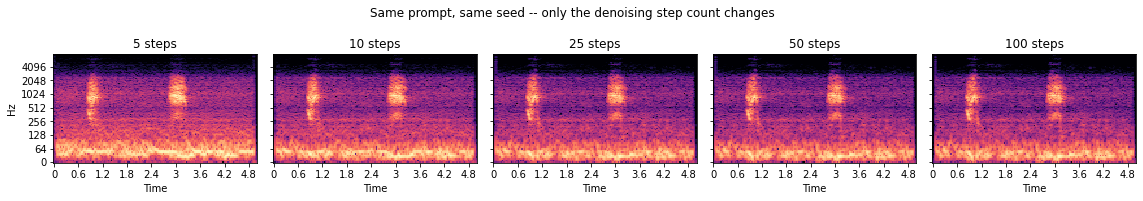

In [14]:
# Same seed, same prompt, different step counts -- so the ONLY variable is the loop length.
fig, axes = plt.subplots(1, len(step_clips), figsize=(16, 2.8), sharey=True)
for ax, (n, clip) in zip(axes, step_clips.items()):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(clip)), ref=np.max)
    librosa.display.specshow(S, sr=AUDIOLDM_SR, x_axis="time", y_axis="log", ax=ax)
    ax.set_title(f"{n} steps")
    ax.label_outer()
plt.suptitle("Same prompt, same seed -- only the denoising step count changes")
plt.tight_layout()
plt.show()

**Note what the step count does *not* affect: the length of the audio.**

Generating 10 seconds instead of 5 would use the *same* 50 steps. Compare with WaveNet,
where 10 seconds costs 160,000 sequential passes instead of 80,000. That decoupling is the
entire escape.

## 5. The comparison: diffusion vs token LM

The same prompt, generated two ways:

| | **AudioGen**  | **AudioLDM** (this notebook) |
|---|---|---|
| Paradigm | Autoregressive transformer over **discrete tokens** | **Diffusion** in a continuous latent |
| Loop runs over | time (50 tokens/sec) | noise level (50 steps, fixed) |
| Output length | variable; can **continue** audio | fixed at generation time |
| Renders waveform with | EnCodec's GAN decoder | HiFi-GAN vocoder |

Both took Escape routes out of WaveNet's bottleneck. Listen to what each produced.

In [16]:
print(f'PROMPT: "{SHARED_PROMPT}"\n')

print("[1] REAL  -- UrbanSound8K dog_bark (ground truth for the 'dog' half)")
display(Audio(real_dog, rate=AUDIOLDM_SR))

print("[2] AUDIOLDM -- latent diffusion")
display(Audio(audioldm_clip, rate=AUDIOLDM_SR))

PROMPT: "a dog barking while a car passes by"

[1] REAL  -- UrbanSound8K dog_bark (ground truth for the 'dog' half)


[2] AUDIOLDM -- latent diffusion


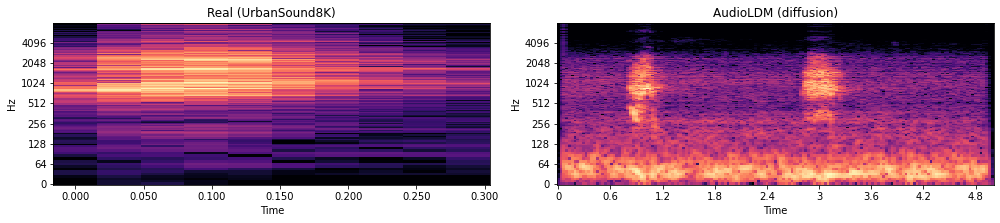

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.2))
panels = [
    (real_dog,       AUDIOLDM_SR, "Real (UrbanSound8K)"),
    (audioldm_clip,  AUDIOLDM_SR, "AudioLDM (diffusion)"),
]
for ax, (sig, sr, title) in zip(axes, panels):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(sig.astype(np.float32))), ref=np.max)
    librosa.display.specshow(S, sr=sr, x_axis="time", y_axis="log", ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 6. Score them with CLAP

Which paradigm matched the prompt better? Neither has a reference to compare against — so
we ask CLAP whether the audio and the text agree.

We also score against a **mismatched** prompt. If the metric cannot separate those, it is
measuring nothing.

In [19]:
from transformers import ClapModel, ClapProcessor

clap      = ClapModel.from_pretrained("laion/clap-htsat-unfused").to(DEVICE).eval()
clap_proc = ClapProcessor.from_pretrained("laion/clap-htsat-unfused")

CLAP_SR = 48000

def clap_score(waveform, sr, text):
    wav = librosa.resample(np.asarray(waveform, dtype=np.float32),
                           orig_sr=sr, target_sr=CLAP_SR)
    a_in = clap_proc(audios=wav, sampling_rate=CLAP_SR, return_tensors="pt").to(DEVICE)
    t_in = clap_proc(text=[text], return_tensors="pt", padding=True).to(DEVICE)
    with torch.no_grad():
        ae = clap.get_audio_features(**a_in)
        te = clap.get_text_features(**t_in)
    ae = ae / ae.norm(dim=-1, keepdim=True)
    te = te / te.norm(dim=-1, keepdim=True)
    return float((ae @ te.T).item())

In [20]:
MISMATCH = "a solo piano playing a gentle melody"

rows = [
    ("Real (UrbanSound8K)",   real_dog,       AUDIOLDM_SR),
    ("AudioLDM (diffusion)",  audioldm_clip,  AUDIOLDM_SR),
]

print(f'prompt   : "{SHARED_PROMPT}"')
print(f'mismatch : "{MISMATCH}"\n')
print(f"{'clip':<26} {'prompt':>9} {'mismatch':>10} {'gap':>8}")
print("-" * 56)
for name, clip, sr in rows:
    p = clap_score(clip, sr, SHARED_PROMPT)
    m = clap_score(clip, sr, MISMATCH)
    print(f"{name:<26} {p:>9.3f} {m:>10.3f} {p-m:>8.3f}")

prompt   : "a dog barking while a car passes by"
mismatch : "a solo piano playing a gentle melody"

clip                          prompt   mismatch      gap
--------------------------------------------------------
Real (UrbanSound8K)            0.323     -0.155    0.478
AudioLDM (diffusion)           0.473      0.108    0.365


In [21]:
# Does the step count change the CLAP score?
# If quality improves with more steps, prompt-adherence should too -- but only up to a point.
print(f"{'steps':>6} {'CLAP score':>12}")
print("-" * 20)
for n, clip in step_clips.items():
    print(f"{n:>6} {clap_score(clip, AUDIOLDM_SR, SHARED_PROMPT):>12.3f}")

 steps   CLAP score
--------------------
     5        0.162
    10        0.262
    25        0.434
    50        0.473
   100        0.490


### Read the table carefully

A few things worth pointing out to students:

- **The real clip does not necessarily win.** A generated clip can score *higher* than a
  real recording, because it was optimised (via guidance) to be an obvious, prototypical
  match to the text. Reality is messier than a caption.

- **The gap matters more than the absolute number.** CLAP scores are not calibrated. A raw
  score of 0.4 means nothing on its own; a *gap* of 0.3 between the correct and the
  mismatched prompt means the metric is discriminating.

- **More denoising steps do not monotonically improve the CLAP score.** Quality and
  prompt-adherence are different axes.

This is the circularity problem from the slides: we are grading a generator with a model
trained on the same kind of data. **A model tuned to maximise CLAP learns to please CLAP —
which is not the same as pleasing a listener.** Always listen.

## 6. What to take away

1. **Diffusion escaped the bottleneck differently.** Its loop runs over *noise level*, not *time*. Each step denoises the entire clip at once, so the number of steps is decoupled from the length of the audio — generating 10 seconds uses the same steps as 5. That decoupling is the whole escape.

2. **The step count is a dial you set at inference.** You heard quality climb from 5 steps to 100, and the CLAP score rise with it. Fewer steps is faster and coarser; more steps is slower and cleaner. Neither a GAN nor a token LM gives you this knob after training.

3. **AudioLDM is every paradigm stacked.** A VAE compresses the mel-spectrogram, diffusion generates in that compressed latent, and a GAN vocoder renders the waveform. These are not competitors — they are components of one system.

4. **Compression is what made it cheap.** AudioLDM diffuses in a *latent* space, not on the raw waveform. Lab 6D's MusicGen predicted *tokens*, not samples. Both models won by refusing to work at full resolution — the same lesson reached by two different routes.

5. **Evaluation remains genuinely unsolved.** A generated clip can even out-score a real recording on CLAP, because it was steered to be a prototypical match to the caption while reality is messier. You have a number; you do not have the truth. **The gap between the matched and mismatched prompt is the signal — not the raw score — and no metric replaces listening.**

---
